<a href="https://colab.research.google.com/github/zxokam/Linear-Regression-ML-model/blob/main/Linear_Regression_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import datasets
import Lin_Req_Model as lrm

Load dataset

In [41]:
diabetes = datasets.load_diabetes()

In [42]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]]),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142., 155., 225.,  59

Description of the Diabetes dataset

In [43]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

Feature name

In [44]:
print(diabetes.feature_names)

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


Create X and Y data matrices

In [45]:
X = diabetes.data
Y = diabetes.target

Load dataset + Create X and Y data matrices (in 1 step)

In [47]:
X, Y = datasets.load_diabetes(return_X_y=True)

In [59]:
X.shape, Y.shape

((442, 10), (442,))

Data Pre-Processing

In [62]:
diabetes = pd.read_csv('https://www4.stat.ncsu.edu/~boos/var.select/diabetes.tab.txt', sep='\t')

In [63]:
diabetes.head()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
0,59,2,32.1,101.0,157,93.2,38.0,4.0,4.8598,87,151
1,48,1,21.6,87.0,183,103.2,70.0,3.0,3.8918,69,75
2,72,2,30.5,93.0,156,93.6,41.0,4.0,4.6728,85,141
3,24,1,25.3,84.0,198,131.4,40.0,5.0,4.8903,89,206
4,50,1,23.0,101.0,192,125.4,52.0,4.0,4.2905,80,135


In [64]:
diabetes.tail()

,AGE,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,Y
437,60,2,28.2,112.00,185,113.8,42.0,4.00,4.9836,93,178
438,47,2,24.9,75.00,225,166.0,42.0,5.00,4.4427,102,104
439,60,2,24.9,99.67,162,106.6,43.0,3.77,4.1271,95,132
440,36,1,30.0,95.00,201,125.2,42.0,4.79,5.1299,85,220
441,36,1,19.6,71.00,250,133.2,97.0,3.00,4.5951,92,57


In [65]:
diabetes.shape

(442, 11)

In [66]:
diabetes.isnull().sum()

,0
AGE,0
SEX,0
BMI,0
BP,0
S1,0
S2,0
S3,0
S4,0
S5,0
S6,0


Training the Linear Regression model

### Fixing Target Selection and Scaling Features
We will update $Y$ to use the correct target column (disease progression `Y`) and standardize $X$ using `StandardScaler` to prevent the numerical gradient explosion.

In [74]:
from sklearn.preprocessing import StandardScaler

# 1. Correct the target extraction (last column 'Y')
X = diabetes.iloc[:, :-1].values
Y = diabetes.iloc[:, -1].values

# 2. Standardize features to prevent gradient overflow
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Train-test split with scaled features
X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.33, random_state=2)

# 4. Initialize and fit the model
model = lrm.Linear_Regression(learning_rate=0.01, no_of_iterations=1000)
model.fit(X_train, Y_train)

# 5. Display the weights and bias
print('weight = ', model.w[0])
print('bias = ', model.b)

weight =  -3.263687076348476
bias =  152.87254868835356


Predict Data

In [75]:
test_data_prediction = model.predict(X_test)

In [76]:
print(test_data_prediction)

[150.83179735 210.28922634 122.68089834 107.78328995 267.65229122
 244.24696309 114.70346723 119.70948027  90.97197655 190.05141461
 146.45811589 171.67594269 177.32199803 134.33688514 296.63364213
  87.55381998 212.88895732 159.06350552 134.37107065 120.84940982
 140.09067726 176.13561784 158.61910322 177.26412244 125.58085773
 224.12146913 194.65252571 103.88866853  51.15464342 249.02646577
 251.17989196 117.5779673   76.69829071  96.9689536  208.43560747
 167.79116783 157.52279965 193.80316022 113.51259584 243.34021758
 136.81499173 116.33538861 198.02861242 197.00066603 165.68168097
 150.53063661 163.4370947  300.1351157  102.617182   170.16835264
 258.32255014 140.74744694 155.61740659 111.35921134 190.60825821
  87.8404346  131.94845202  73.83621469 161.11915563 161.12677849
 165.59833562 157.55727501  97.24372826 238.20401046 145.89196235
 127.75005742 154.96902871 201.2990231  118.33545524 128.39048228
 212.41168801 199.68197325 120.22321703 156.5458136  148.83605793
 116.87041

Visualizing the predicited values & actual values

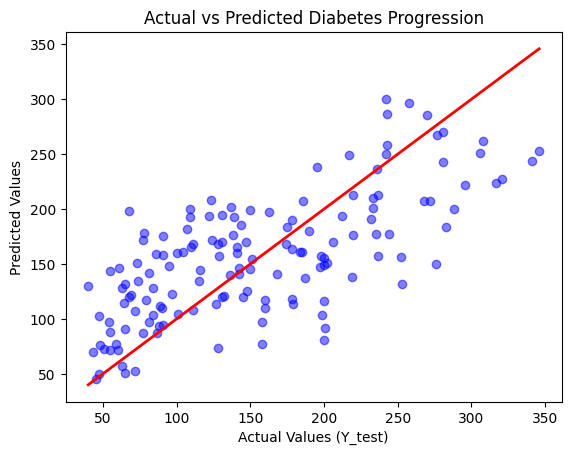

In [79]:
plt.scatter(Y_test, test_data_prediction, color='blue', alpha=0.5)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', lw=2)
plt.xlabel('Actual Values (Y_test)')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Diabetes Progression')
plt.show()

### Visualizing 10D Data in 2D Space
We can use Principal Component Analysis (PCA) to project our 10-dimensional feature space down to 2 dimensions for easy visualization, alongside a correlation heatmap.

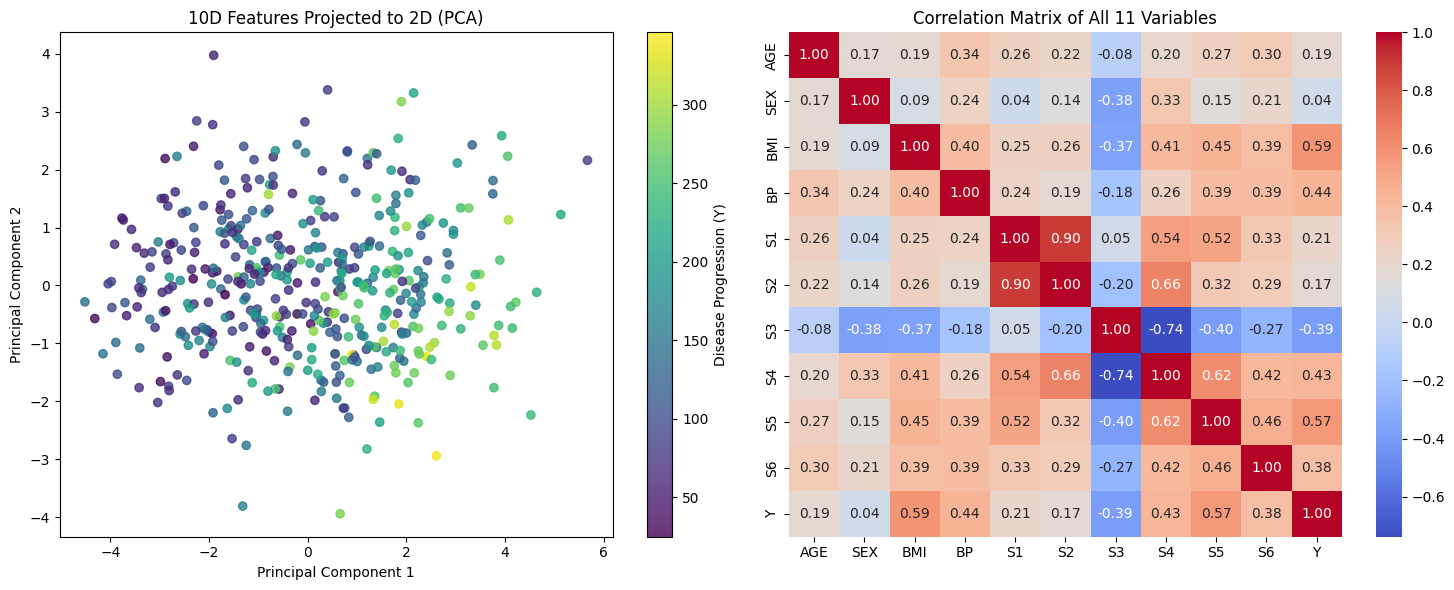

In [80]:
from sklearn.decomposition import PCA
import seaborn as sns

# 1. Project 10D data to 2D using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 2. Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot PCA projection
scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=Y, cmap='viridis', alpha=0.8)
axes[0].set_title('10D Features Projected to 2D (PCA)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
fig.colorbar(scatter, ax=axes[0], label='Disease Progression (Y)')

# Plot Correlation Heatmap
sns.heatmap(diabetes.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Matrix of All 11 Variables')

plt.tight_layout()
plt.show()